In [1]:

import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from qudit_nh_design import *

from matplotlib import rc, rcParams
params = {'legend.fontsize': 15, "axes.labelsize": 15}
rc('text', usetex=True)
rc('xtick', labelsize=14)
rc('ytick', labelsize=14)
rcParams.update(params)

Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]] Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 1.]]


In [2]:
Q = np.zeros([3,3])
Q[2,2]=1
Q=qt.Qobj(Q)
P=1-Q
print(P,Q)

Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]] Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 1.]]


## 1 - Three examples of non-Hermitian dynamics
### 1.1 - Single steady-state, high entropy

In [20]:
N=4
h, J, Omega= 1,8.0, 4.0
tf = 40
nstep = 400
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

print(H_qutrit.isherm,H_qeff.isherm)
psi0 = qt.basis([3]*N,n=[0,1,1,0])
psi0_eff = qt.basis([2]*N,n=[0,1,1,0])
#psi0 = qt.tensor([(qt.basis(3,n=1)+qt.basis(3,n=0)).unit()]*N)
#psi0_eff = qt.tensor([(qt.basis(2,n=1)+qt.basis(2,n=0)).unit()]*N)

Z01 = embedded_pauli('z',0,1)
print(Z01)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
print(qt.expect(e_evo,psi0))
options={'progress':False,'store_states':True}

effective paramters: lambda_1=0.00-0.40j, lambda_2=0.00-1.60j
True False
Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
[ 1. -1. -1.  1.]


In [21]:
res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options=options)
'''
res_rand = time_evo(H_qutrit,psi0,trand,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options={'uniform_dt':False, 'progress':False})
'''

res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)

[Quantum object: dims=[[3, 3, 3, 3], [1, 1, 1, 1]], shape=(81, 1), type='ket', dtype=Dense
 Qobj data =
 [[0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [1.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]
  [0.]],
 Quantum object: dims=[[3, 3, 3, 3], [1, 1, 1, 1]], shape=(81, 1), type='ket', dtype=Dense
 Qobj data =
 [[-1.47243991e-02-2.58154866e-04j]
  [-4.00035317e-05+1.40894292e-03j]
  [ 0.00000000e+00+0.00000000e+00j]
  [ 6.25895055e-03-1.31381710e-01j]
  [-1.16738062e-02-1.10150919e-03j]
  [ 0.00000000e+00+0.00000000e+00j]
  [ 0.0

'\nplt.plot(tvec,res.expect[0])\nplt.plot(tvec,res.expect[1])\n\nplt.plot(trand,res_rand.expect[0],\'-.\')\nplt.plot(trand,res_rand.expect[1],\'-.\')\n\nplt.plot(tvec,res2.expect[0],\'--\')\nplt.plot(tvec,res2.expect[1],\'--\')\nplt.xlabel(r"time $t h_x$")\n'

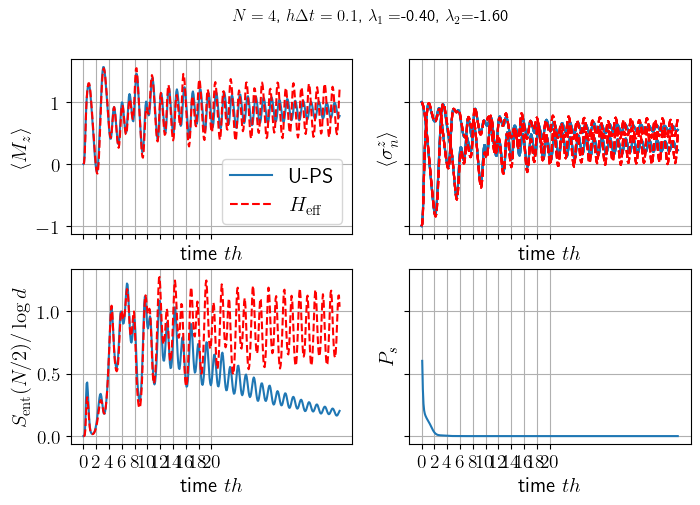

In [25]:

fig,ax = plt.subplots(nrows=2,ncols=2,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$N={N}$, $h\Delta t=0.1$, $\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect)/2,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect)/2,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[1,1].set_xlabel(r'time $t h$')
ax[0,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,22,2))

ax[0,1].grid()
ax[0,1].plot(tvec,np.array(res.expect).T,label='U-PS',c='C0')
ax[0,1].plot(tvec,np.array(res.expect).T,label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,np.array(res2.expect).T,'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,np.array(res2.expect).T,'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')



ax[1,0].plot(tvec,res.entanglement/np.log(2))
ax[1,0].plot(tvec,res2.entanglement/np.log(2),'r--')
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log d$')

ax[1,1].plot(tvec[1:],np.cumprod(np.array(res.measurement_outcomes[1:]))) 
ax[1,1].set_ylabel(r'$P_s$')
ax[1,1].grid()
'''
plt.plot(tvec,res.expect[0])
plt.plot(tvec,res.expect[1])

plt.plot(trand,res_rand.expect[0],'-.')
plt.plot(trand,res_rand.expect[1],'-.')

plt.plot(tvec,res2.expect[0],'--')
plt.plot(tvec,res2.expect[1],'--')
plt.xlabel(r"time $t h_x$")
'''
#fig.savefig(f'N{N}_entangled.pdf',bbox_inches='tight')

### 1.2 Doubly degenerate steady state.

In [38]:
N=4
h, J, Omega= 1,7.2, 5.3
tf = 15
nstep = 150
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

# sanity check that the full Hamiltonian is hermitian while the effective one is not
print(f"Hermiticity of full qutrit Hamiltonian:{H_qutrit.isherm}, effective Hamiltonian:{H_qeff.isherm})

psi0 = qt.basis([3]*N,n=[0,1]*(N//2))
psi0_eff = qt.basis([2]*N,n=[0,1]*(N//2))

#local observable      
Z01 = embedded_pauli('z',0,1)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
      
options={'progress':False}

res_qutrit = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options=options)

res_effective = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)

effective paramters: lambda_1=0.00-0.70j, lambda_2=0.00-1.30j
True False
Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
[ 1. -1.  1. -1.  1. -1.]


TypeError: Input is not a quantum object

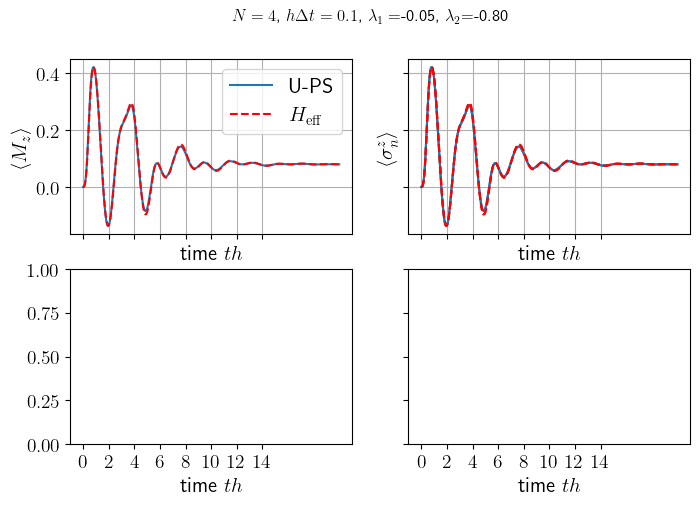

In [9]:

fig,ax = plt.subplots(nrows=2,ncols=2,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$N={N}$, $h\Delta t={tf/nstep:.1f}$, $\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect)/N,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect)/N,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[1,1].set_xlabel(r'time $t h$')
ax[0,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,16,2))

ax[0,1].grid()
ax[0,1].plot(tvec,np.array(res.expect[0::2]).mean(axis=0),label='U-PS',c='C0')
ax[0,1].plot(tvec,np.array(res.expect[1::2]).mean(axis=0),label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,np.array(res2.expect[0::2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,np.array(res2.expect[1::2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')



ax[1,0].plot(tvec,get_entanglement(res.states,[j for j in range(N//2)])/np.log(3))
ax[1,0].plot(tvec,get_entanglement(res2.states,[j for j in range(N//2)])/np.log(2),'r--')
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log d$')

ax[1,1].plot(tvec[1:],np.cumprod(np.array(res.measurement_outcomes[1:]))) 
ax[1,1].set_ylabel(r'$P_s$')
ax[1,1].grid()
#fig.savefig('N{N}_oscillatory.pdf',bbox_inches='tight')

### 1.3 Single steady state, low entropy

In [42]:
N=6
h, J, Omega= 1,3.5, 5.1*np.sqrt(2)
tf = 15
nstep = 150
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

print(H_qutrit.isherm,H_qeff.isherm)
psi0 = qt.basis([3]*N,n=[0,1]*(N//2))
psi0_eff = qt.basis([2]*N,n=[0,1]*(N//2))

Z01 = embedded_pauli('z',0,1)
print(Z01)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
print(qt.expect(e_evo,psi0))
options={'progress':False}

res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options=options)

#res_rand = time_evo(H_qutrit,psi0,trand,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
#               force_proj=True,options={'uniform_dt':False, 'progress':False})

res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)

effective paramters: lambda_1=0.00-1.30j, lambda_2=0.00-0.31j
True False
Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
[ 1. -1.  1. -1.  1. -1.]


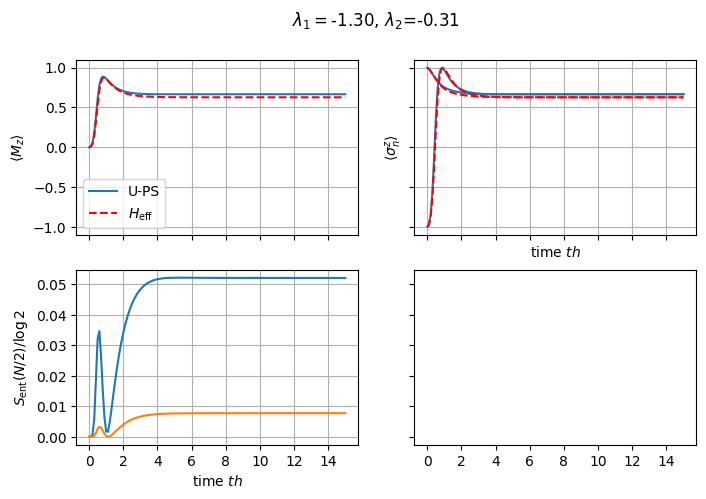

In [135]:

fig,ax = plt.subplots(nrows=2,ncols=2,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$N={N}$, $h\Delta t={tf/nstep:.1f}$, $\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect)/2,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect)/2,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[1,1].set_xlabel(r'time $t h$')
ax[0,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,16,2))

ax[0,1].grid()
ax[0,1].plot(tvec,np.array(res.expect[0::2]).mean(axis=0),label='U-PS',c='C0')
ax[0,1].plot(tvec,np.array(res.expect[1::2]).mean(axis=0),label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,np.array(res2.expect[0::2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,np.array(res2.expect[1::2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')



ax[1,0].plot(tvec,get_entanglement(res.states,[j for j in range(N//2)])/np.log(3))
ax[1,0].plot(tvec,get_entanglement(res2.states,[j for j in range(N//2)])/np.log(2),'r--')
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log d$')

ax[1,1].plot(tvec[1:],np.cumprod(np.array(res.measurement_outcomes[1:]))) 
ax[1,1].set_ylabel(r'$P_s$')
ax[1,1].grid()

fig.savefig('N{N}_separable.pdf',bbox_inches='tight')

## 2 - Phase diagram

In [8]:
N = 4
h=1
ns=100
lambda1_list=np.linspace(0.01,2.5,ns)
lambda2_list=np.linspace(0.01,2.5,ns)
gs_multiplicity4 = []
gs_entropy4 = []
gs_gap4 =[]
for lam1 in lambda1_list:
    for lam2 in lambda2_list:
        heff, lambda1, lambda2 = h, -1j*lam1, -1j*lam2
        #print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
        single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
        two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
        H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)
        res = nh_stationary_states(H_qeff,N, tol=1e-8,d=2)
        gs_multiplicity4.append(res.degeneracy)
        gs_entropy4.append(np.array(res.entanglement_entropies).mean())      
        gs_gap4.append(-(res.steady_eigenvalue[-1]-res.steady_eigenvalue[0]).imag)

In [7]:
gs_multiplicity = np.loadtxt("../results/Data/Data/N8_gsmultiplicity_lam2.5_ns100.csv",delimiter=',')
gs_gap = np.loadtxt("../results/Data/Data/N8_gsgap_lam2.5_ns100.csv",delimiter=',')
gs_entropy = np.loadtxt("../results/Data/Data/N8_gsentropy_lam2.5_ns100.csv",delimiter=',')
ns=100
lambda1_list=np.linspace(0.01,2.5,ns)/2
lambda2_list=np.linspace(0.01,2.5,ns)/2

C:\Users\matte\AppData\Local\Temp\ipykernel_25860\3768946791.py:9: UserWarning: The following kwargs were not used by contour: 'label'
  ax[0].contour(2*X,2*Y,np.array(gs_multiplicity2).reshape([ns,ns]),levels=1,colors='C0',label='N=2')


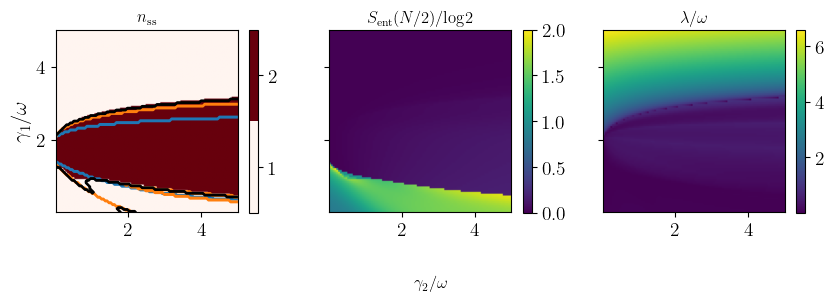

In [50]:
N=8
fig, ax = plt.subplots(ncols=3,sharex=True, sharey=True)
fig.set_size_inches([10,3.5])
fig.supxlabel(r'$\gamma_2/\omega$')
ax[0].set_ylabel(r'$\gamma_1/\omega$')
im=ax[0].imshow(np.array(gs_multiplicity).reshape([ns,ns]),origin='lower',
                extent=[0.02,5,0.02,5],cmap='Reds')
X,Y = np.meshgrid(lambda2_list,lambda1_list)
ax[0].contour(2*X,2*Y,np.array(gs_multiplicity2).reshape([ns,ns]),levels=1,colors='C0')
ax[0].contour(2*X,2*Y,np.array(gs_multiplicity4).reshape([ns,ns]),levels=1,colors='C1')
ax[0].contour(2*X,2*Y,np.array(gs_multiplicity6).reshape([ns,ns]),levels=2,colors='k')
fig.colorbar(im,ax=ax[0],shrink=0.68,boundaries=[0.5,1.5,2.5],values=[1,2],ticks=[1,2])
ax[0].set_title(r'$n_{\rm ss}$')
im=ax[1].imshow(np.array(gs_entropy).reshape([ns,ns])/np.log(2),origin='lower',
                extent=[0.02,5,0.02,5],vmin=0,vmax=2)
fig.colorbar(im,ax=ax[1],shrink=0.68,ticks=[0,0.5,1.0,1.5,2.0])
ax[1].set_title(r'$S_{\rm ent}(N/2)/{\rm log}2$')

im=ax[2].imshow((np.array(gs_gap)).reshape([ns,ns])/np.log(2),origin='lower',
                extent=[0.02,5,0.02,5])
fig.colorbar(im,ax=ax[2],shrink=0.68)
ax[2].set_title(r'$\lambda/\omega$')

fig.savefig(f'phase_diagram_N{N}.pdf',bbox_inches='tight')

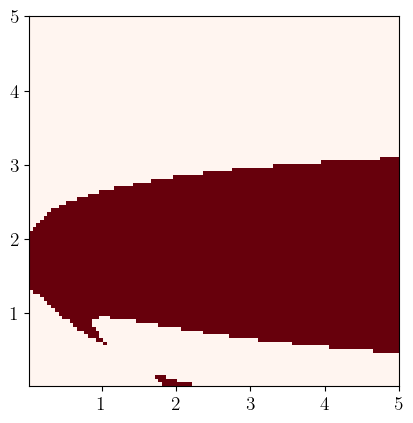

In [77]:
plt.imshow(np.array(gs_multiplicity6).reshape([ns,ns]),origin='lower',
                extent=[0.02,5,0.02,5],cmap='Reds')

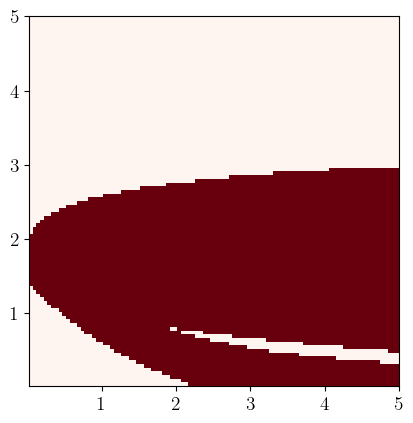

In [9]:
plt.imshow(np.array(gs_multiplicity4).reshape([ns,ns]),origin='lower',
                extent=[0.02,5,0.02,5],cmap='Reds')

## Full stocastic dynamics

In [39]:
N=4
h, J, Omega= 1,4, 0.5
tf = 15
nstep = 150
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
psi0 = qt.basis([3]*N,n=[0,1]*(N//2))

Z01 = embedded_pauli('z',0,1)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]

res=run_trajectories(H_qutrit, psi0, tvec, P,N, measured_sites=[j for j in range(N)], 
                     ntraj = 100, e_ops = e_evo,n_jobs=10)

effective paramters: lambda_1=0.00-0.01j, lambda_2=0.00-0.40j


In [41]:
res=run_trajectories(H_qutrit, psi0, tvec, P,N, measured_sites=[j for j in range(N)], 
                     ntraj = 100, e_ops = e_evo,n_jobs=10)

Running 100 trajectories on 10 workers...


Trajectories: 100%|█████████████████████████████████████████████████████████████| 100/100 [00:29<00:00,  3.42traj/s]


In [10]:
def success_until_t(ps):
    for ntr, traj in enumerate(ps):
        for ist, pst in enumerate(traj):
            if not pst:
                traj[ist+1:]=False
                continue
        ps[ntr] = traj
    return ps

[]

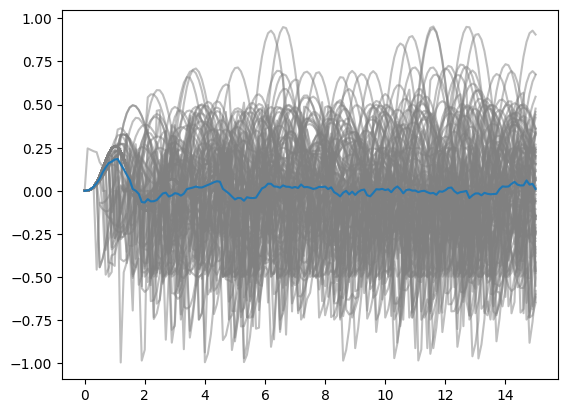

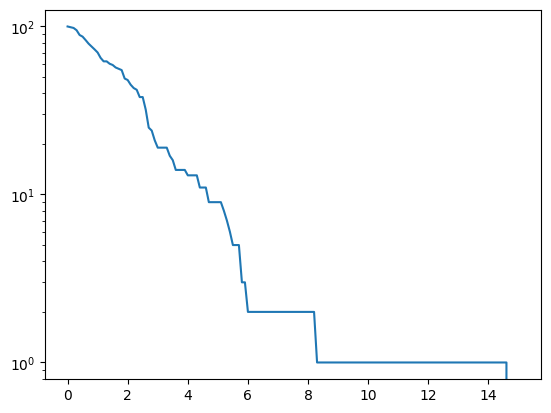

In [42]:
plt.plot(tvec,np.array(res.expect_traj).mean(axis=0).T,c='gray',alpha=0.5);
plt.plot(tvec,np.array(res.expect_mean).mean(axis=0))
plt.figure()
plt.plot(tvec,np.array(success_until_t(res.proj_traj)).sum(axis=0))
plt.semilogy()

## Comparison between diffeernt points in the phase diagram

effective paramters: lambda_1=0.00-0.00j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.01j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.03j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.05j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.08j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.11j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.15j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.20j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.25j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.31j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.38j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.45j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.53j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.61j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.70j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.80j, lambda_2=0.00-0.05j
effectiv

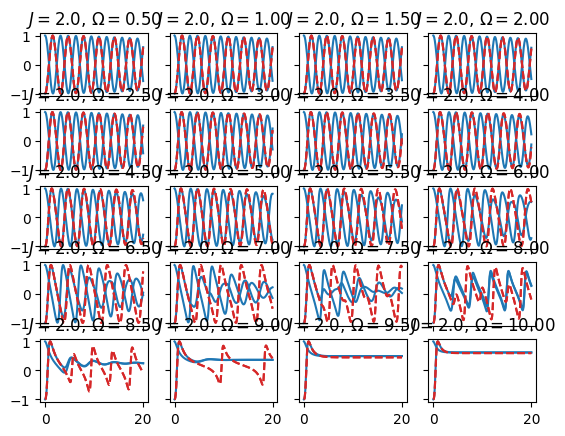

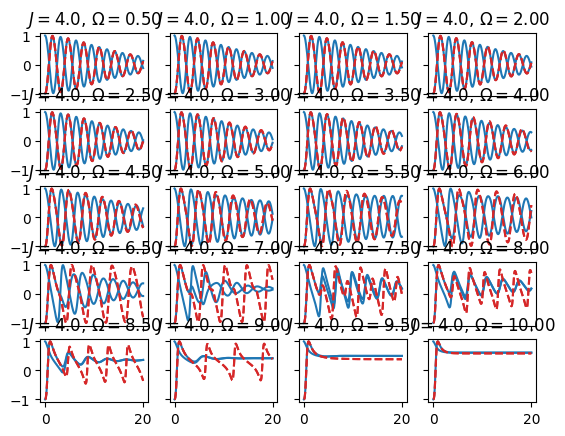

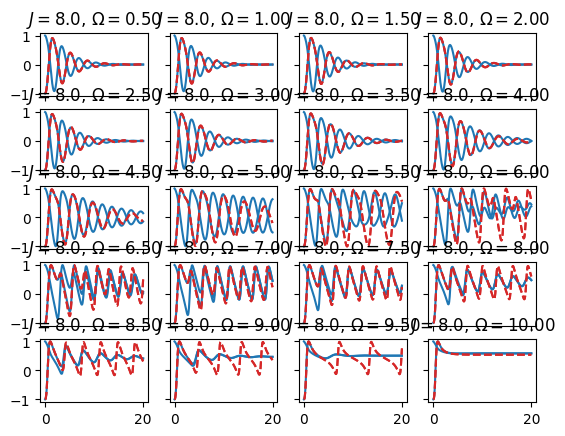

In [23]:
omega_list = np.linspace(0.5,10,20)
J_list = np.array([2.0,4.0,8.0])
Z01 = embedded_pauli('z',0,1)
tf = 20
nstep = 400
rate=nstep/tf
tvec = np.linspace(0,tf,nstep+1)
N=2
h=1

e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
data_dict=dict()

for J in J_list:
    fig, ax = plt.subplots(ncols=4,nrows=5,sharex=True, sharey=True)
    for iom, Omega in enumerate(omega_list):

        #--- full Hamiltonian with measurements
        single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
        two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
        H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)
        
        #--- target effective Hamiltonian
        heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
        print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
        single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
        two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
        H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)
    
        psi0 = qt.basis([3]*N,n=[0,1]*(N//2))
        psi0_eff = qt.basis([2]*N,n=[0,1]*(N//2))
    
        options={'progress':False}
        
        res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
                       force_proj=True,options=options)
    
        res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)
        data_dict['qutrit', J, Omega] = res.expect
        data_dict['eff', J, Omega] = res2.expect
        ax[iom//4,np.mod(iom,4)].set_title(rf"$J={J:.1f}$, $\Omega={Omega:.2f}$")
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(res.expect[0::2]).mean(axis=0),label='U-PS',c='C0')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(res.expect[1::2]).mean(axis=0),label='U-PS',c='C0')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(res2.expect[1::2]).mean(axis=0),'--',label='U-PS',c='C3')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(res2.expect[1::2]).mean(axis=0),'--',label='U-PS',c='C3')
        data_dict['err',J, Omega] = np.abs(np.array(res.expect)-np.array(res2.expect)).sum(axis=0)

In [ ]:
omega_list = np.linspace(0.5,10,20)
J_list = np.array([2.0,4.0,8.0])
Z01 = embedded_pauli('z',0,1)
tf = 20
nstep = 400
rate=nstep/tf
tvec = np.linspace(0,tf,nstep+1)
N=2
h=1


for J in J_list:
    fig, ax = plt.subplots(ncols=4,nrows=5,sharex=True, sharey=True)
    fig.set_size_inches([12,15])
    for iom, Omega in enumerate(omega_list):
        lambda1, lambda2 = Omega**2/rate/4, J**2/rate/4
        ax[iom//4,np.mod(iom,4)].set_title(rf"$\lambda_1={lambda1:.2f}$, $\lambda_2={lambda2:.2f}$")
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(data_dict['qutrit', J, Omega][0::2]).mean(axis=0),label='U-PS',c='C0')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(data_dict['qutrit', J, Omega][1::2]).mean(axis=0),label='U-PS',c='C0')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(data_dict['eff', J, Omega][0::2]).mean(axis=0),'--',label='U-PS',c='C3')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(data_dict['eff', J, Omega][1::2]).mean(axis=0),'--',label='U-PS',c='C3')
        fig.supxlabel(r'$\omega t$')
        fig.supylabel(r'$\langle \sigma^z_{e/o} \rangle$')

        fig.savefig(f'comparison_N{N}_rate{rate:.2f}.pdf',bbox_inches='tight')

                      


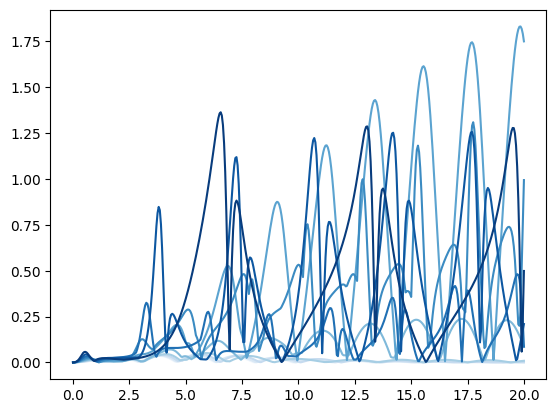

In [21]:
col = plt.cm.Blues(omega_list/max(omega_list))
J=8.0
for iom, omega in enumerate(omega_list[::2]):
    plt.plot(tvec, data_dict['err',J, omega],c=col[2*iom])

### Comparison between system sizes: entanglement

2 1
4 2
6 1
8 1
10 1
12 1


Text(0, 0.5, '$S_{\\rm ent}(N/2)$')

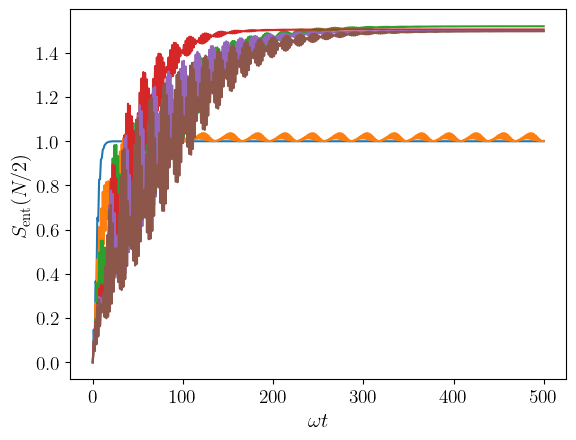

In [26]:
Omega = 4.0
Z01 = embedded_pauli('z',0,1)
tf = 500
nstep = 500
rate=nstep/tf
tvec = np.linspace(0,tf,nstep+1)
N_list=[2,4,6,8,10,12]
h=1
lambda1=0.2
lambda2=0.8
#data_dict=dict()
opts={'progress':False}
for N in N_list:
    #--- full Hamiltonian with measurements
    e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
    single_body_eff = [[h, ('x', 0, 1), None], [-2j*lambda1, ('p-', 0, 1), None] ]
    two_body_eff=[[-2j*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
    H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)
    res_nh = nh_stationary_states(H_qeff,N, tol=1e-8,d=2)
    psi0_eff = qt.basis([2]*N,n=[0,1]*(N//2))
    print(N, res_nh.degeneracy)
    options={'progress':False}

    res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff,options=opts)
    data_dict['eff', N, lambda1, lambda2] = res2.expect
    data_dict['ent', N, lambda1, lambda2] = res2.entanglement
    data_dict['sse', N, lambda1, lambda2] =res_nh.entanglement_entropies
    plt.plot(tvec, res2.entanglement/np.log(2),label=rf'$N={N}$')

    
plt.xlabel(r'$\omega t$')
plt.ylabel(r"$S_{\rm ent}(N/2)$" )

Text(0, 0.5, '$\\langle \\sigma^z \\rangle $')

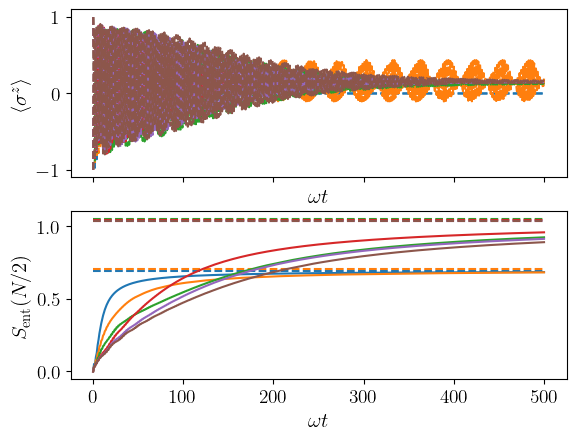

In [27]:
fig,ax=plt.subplots(nrows=2,sharex=True)
N_list=[2,4,6,8,10,12]
clist=['C0','C1','C2','C3','C4','C5']
ent_pippo=[]
for ni, N in enumerate(N_list[:]):
    ax[0].plot(tvec,np.array(data_dict['eff', N,lambda1,lambda2][0::2]).mean(axis=0),'--',label=rf'$N={N}$',
               c=clist[ni])
    ax[0].plot(tvec,np.array(data_dict['eff', N,lambda1,lambda2][1::2]).mean(axis=0),'--',
               c=clist[ni])
    
    #ax[1].plot(tvec,data_dict['ent',N,lambda1,lambda2],c=clist[ni])
    ax[1].plot(tvec,data_dict['ent',N,lambda1,lambda2].cumsum()/np.arange(1,nstep+2),c=clist[ni])
    ent_pippo.append((data_dict['ent',N,lambda1,lambda2].cumsum()/np.arange(1,nstep+2))[-1])
    ax[1].plot(tvec,tvec*0+np.array(data_dict['sse',N,lambda1,lambda2]).mean(),'--', c=clist[ni])
ax[0].set_xlabel(r'$\omega t$')
ax[1].set_xlabel(r'$\omega t$')
ax[1].set_ylabel(r"$S_{\rm ent}(N/2)$" )
ax[0].set_ylabel(r"$\langle \sigma^z \rangle $" )

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (6,) + inhomogeneous part.

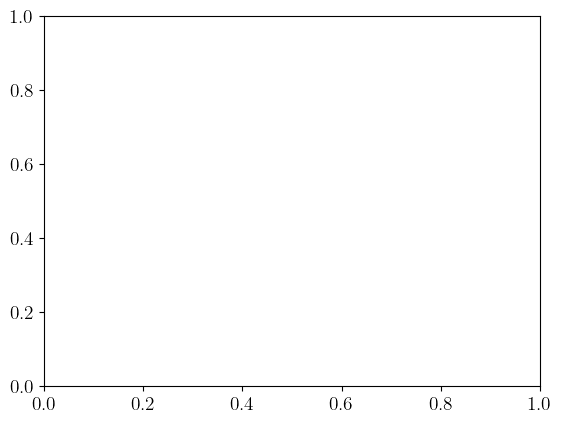

In [28]:
plt.plot(N_list,[data_dict['sse',N,lambda1,lambda2] for N in N_list],'.-')
plt.plot(N_list,0.5+np.log(np.array(N_list)**0.2),'.-')

plt.semilogx()

In [29]:
np.save(f'data_long_time.npy',data_dict,allow_pickle=True)

[]

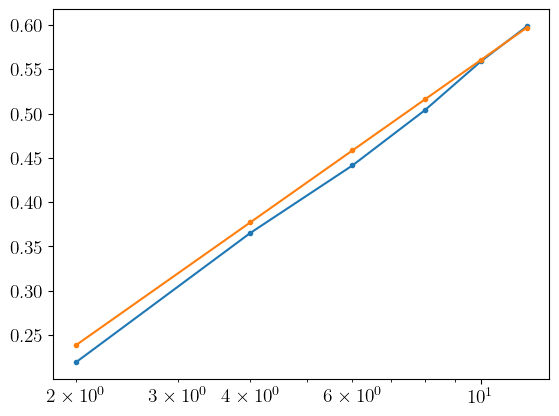

In [62]:
plt.plot(N_list,ent_pippo,'.-')
plt.plot(N_list,0.1+0.2*np.log(np.array(N_list)),'.-')

plt.semilogx()

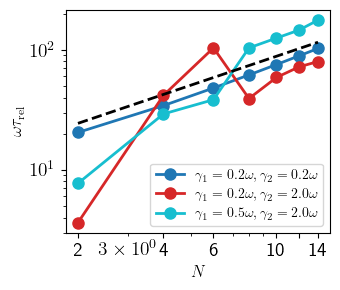

In [2]:

# Load the data
data = np.loadtxt('relaxation_rates.csv', delimiter=',', skiprows=0)
N_vals = data[:, 0].astype(int)
lambda1_vals = data[:, 1]
lambda2_vals = data[:, 2]
relaxation_rates = data[:, 3]
entanglement = data[:,4]
# Get unique (lambda1, lambda2) pairs
unique_points = np.unique(np.column_stack([lambda1_vals, lambda2_vals]), axis=0)

# Create figure
fig, ax = plt.subplots(figsize=(3.5, 3))


# Colors for different points
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_points)))

# Plot data for each (lambda1, lambda2) point
for idx, (lam1, lam2) in enumerate(unique_points):
    if lam2 == 2.25:
        continue
    mask = (lambda1_vals == lam1) & (lambda2_vals == lam2)
    N_subset = N_vals[mask]
    rate_subset = relaxation_rates[mask]
    
    # Sort by N for proper plotting
    sort_idx = np.argsort(N_subset)
    N_subset = N_subset[sort_idx]
    rate_subset = rate_subset[sort_idx]
    
    ax.plot(N_subset, 1/rate_subset, 'o-', color=colors[idx], 
            label=rf'$\gamma_1={2*lam1:.1f}\omega, \gamma_2={2*lam2:.1f}\omega$', linewidth=2, markersize=8)

ax.plot(N_subset,14*N_subset**(0.8),'k--',lw=2)
ax.set_xlabel(r'$N$', fontsize=12)
ax.set_ylabel(r'$\omega \tau_{\rm rel}$', fontsize=12)
#ax.set_title(r'Relaxation rate vs system size', fontsize=14)
ax.loglog()
ax.legend(fontsize=10, loc='best')
#ax.grid(True, alpha=0.3)
ax.set_xticks([2,4,6,10,12,14],labels=["2", "4", "6", "10"," ", "14"])

fig.tight_layout()
#fig.savefig('relaxation_rates.pdf', bbox_inches='tight')
plt.show()

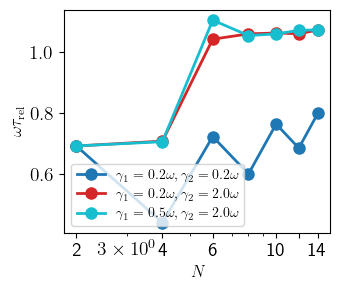

In [3]:
# Plot data for each (lambda1, lambda2) point
fig, ax = plt.subplots(figsize=(3.5, 3))

for idx, (lam1, lam2) in enumerate(unique_points):
    if lam2 == 2.25:
        continue
    mask = (lambda1_vals == lam1) & (lambda2_vals == lam2)
    N_subset = N_vals[mask]
    sse_subset = entanglement[mask]
    
    # Sort by N for proper plotting
    sort_idx = np.argsort(N_subset)
    N_subset = N_subset[sort_idx]
    sse_subset = sse_subset[sort_idx]
    
    ax.plot(N_subset, sse_subset, 'o-', color=colors[idx], 
            label=rf'$\gamma_1={2*lam1:.1f}\omega, \gamma_2={2*lam2:.1f}\omega$', linewidth=2, markersize=8)

#ax.plot(N_subset,14*N_subset**(0.8),'k--',lw=2)
ax.set_xlabel(r'$N$', fontsize=12)
ax.set_ylabel(r'$\omega \tau_{\rm rel}$', fontsize=12)
#ax.set_title(r'Relaxation rate vs system size', fontsize=14)
ax.semilogx()
ax.legend(fontsize=10, loc='best')
#ax.grid(True, alpha=0.3)
ax.set_xticks([2,4,6,10,12,14],labels=["2", "4", "6", "10"," ", "14"])

fig.tight_layout()
#fig.savefig('relaxation_rates.pdf', bbox_inches='tight')
plt.show()

In [10]:
2**14

16384

## load external data

In [2]:
from analyse_data import * 
def _exp_decay(t, A, gamma):
    """A * exp(-gamma * t) + C"""
    return A -gamma * t


def fit_success_prob(times, succ_PS):
    """
    Fit P_success(t) = A * exp(-gamma * t) + C.

    Parameters
    ----------
    times      : (n_times,) array
    succ_PS    : (n_times,) bool array from post-selected run
    smooth_window : int, light smoothing before fit

    Returns
    -------
    dict with keys: A, gamma, C, A_err, gamma_err, C_err, fit_ok
    """
    y = succ_PS.astype(float)
    t = times

    # Initial guess: decaying from ~1 to ~0
    p0 = [1, 1.0 / (t[-1] - t[0] + 1e-9)]
    bounds = ([-1, 0], [1, 100/t[1]])

    try:
        popt, pcov = curve_fit(_exp_decay, t, np.log(y), p0=p0, bounds=bounds,
                               maxfev=10000)
        perr = np.sqrt(np.diag(pcov))
        return dict(A=popt[0], gamma=popt[1],
                    A_err=perr[0], gamma_err=perr[1],
                    fit_ok=True)
    except (RuntimeError, ValueError) as e:
        warnings.warn(f"Exponential fit failed: {e}")
        return dict(A=np.nan, gamma=np.nan,
                    A_err=np.nan, gamma_err=np.nan,
                    fit_ok=False)

In [3]:
data=dict()

In [11]:

omega_list = np.arange(1.0,11.0,1.0)
N_list = [2,4,6,8]
J=7.0
for N in N_list:
    for omega in omega_list:
        fpath = f"../results/data_N{N}_h1.0_J{J}_Om{omega:.1f}_tf20.0_nstep200_ntraj1_forceProjFalse.npz"
        print(fpath)
        data_tmp   = np.load(fpath,allow_pickle=True)
        params = load_params(fpath)
        data[N,J,omega, 'ps_exp']  = data_tmp["ps_expect"]      # (N, n_times)
        data[N,J,omega, 'eff_exp'] = data_tmp["eff_expect"]     # (N, n_times)
        data[N,J,omega, 'ps_ee']   = data_tmp["ps_entanglement"]
        data[N,J,omega, 'eff_ee']  = data_tmp["eff_entanglement"]
        times = data_tmp["times"]
        data[N,J,omega,'ps_rdm'] = data_tmp["ps_reduced_norm"]

../results/data_N2_h1.0_J7.0_Om1.0_tf20.0_nstep200_ntraj1_forceProjFalse.npz
../results/data_N2_h1.0_J7.0_Om2.0_tf20.0_nstep200_ntraj1_forceProjFalse.npz
../results/data_N2_h1.0_J7.0_Om3.0_tf20.0_nstep200_ntraj1_forceProjFalse.npz
../results/data_N2_h1.0_J7.0_Om4.0_tf20.0_nstep200_ntraj1_forceProjFalse.npz
../results/data_N2_h1.0_J7.0_Om5.0_tf20.0_nstep200_ntraj1_forceProjFalse.npz
../results/data_N2_h1.0_J7.0_Om6.0_tf20.0_nstep200_ntraj1_forceProjFalse.npz
../results/data_N2_h1.0_J7.0_Om7.0_tf20.0_nstep200_ntraj1_forceProjFalse.npz
../results/data_N2_h1.0_J7.0_Om8.0_tf20.0_nstep200_ntraj1_forceProjFalse.npz
../results/data_N2_h1.0_J7.0_Om9.0_tf20.0_nstep200_ntraj1_forceProjFalse.npz
../results/data_N2_h1.0_J7.0_Om10.0_tf20.0_nstep200_ntraj1_forceProjFalse.npz
../results/data_N4_h1.0_J7.0_Om1.0_tf20.0_nstep200_ntraj1_forceProjFalse.npz
../results/data_N4_h1.0_J7.0_Om2.0_tf20.0_nstep200_ntraj1_forceProjFalse.npz
../results/data_N4_h1.0_J7.0_Om3.0_tf20.0_nstep200_ntraj1_forceProjFalse.np

$\gamma_1 = 0.05, \gamma_2 = 2.45$
$\gamma_1 = 0.2, \gamma_2 = 2.45$
$\gamma_1 = 0.45, \gamma_2 = 2.45$
$\gamma_1 = 0.8, \gamma_2 = 2.45$
$\gamma_1 = 1.25, \gamma_2 = 2.45$
$\gamma_1 = 1.8, \gamma_2 = 2.45$
$\gamma_1 = 2.45, \gamma_2 = 2.45$
$\gamma_1 = 3.2, \gamma_2 = 2.45$
$\gamma_1 = 4.05, \gamma_2 = 2.45$
$\gamma_1 = 5.0, \gamma_2 = 2.45$


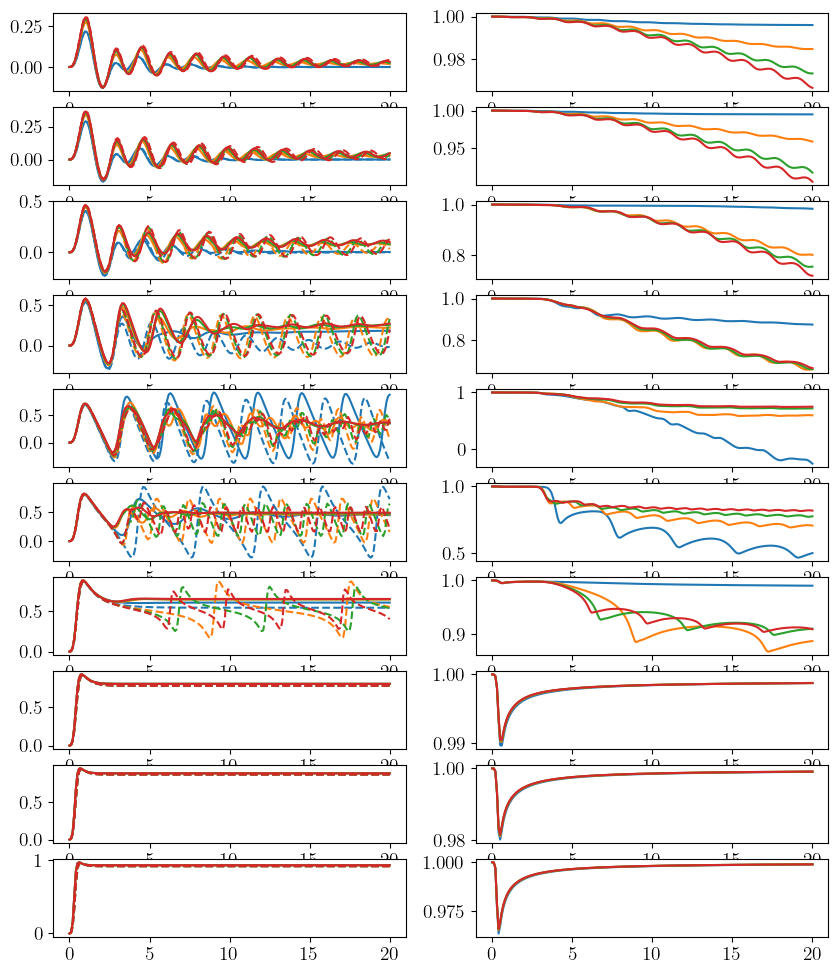

In [13]:
omega_list = np.arange(1.0,11.0,1.0)
fig, ax = plt.subplots(ncols=2,nrows=len(omega_list),figsize=[10,12])
N_list=[2,4,6,8]
J=4.0

for iw, omega in enumerate(omega_list):
    print(f"$\gamma_1 = {omega**2*0.1/2}, \gamma_2 = {49*0.1/2}$")
    for nn, N in enumerate(N_list):
        ax[iw,0].plot(times, data[N,J,omega,'ps_exp'].mean(axis=0), c=f'C{nn}')        
        ax[iw,0].plot(times, data[N,J,omega,'eff_exp'].mean(axis=0), '--', c=f'C{nn}')
                      
        err = 1-(np.cumsum((np.abs(data[N,J,omega,'ps_exp']-data[N,J,omega,'eff_exp'])**2).sum(axis=0))/
                                             np.cumsum((data[N,J,omega,'eff_exp']**2).sum(axis=0)))
        
        ax[iw,1].plot(times,err)
        #ax[iw,2].semilogy(times[1:],np.cumprod(data[N,J,omega,'ps_rdm'][1:]))
        fit_result = fit_success_prob(times[1:],np.cumprod(data[N,J,omega,'ps_rdm'][1:]))
        y_fit  = np.exp(_exp_decay(times, fit_result["A"],
                            fit_result["gamma"]))
        data[N,J,omega,'rate']= fit_result["gamma"]
        #ax[iw,2].semilogy(times,y_fit,'k--')

$\gamma_1 = 0.05, \gamma_2 = 0.8$
$\gamma_1 = 0.2, \gamma_2 = 0.8$
$\gamma_1 = 0.45, \gamma_2 = 0.8$
$\gamma_1 = 0.8, \gamma_2 = 0.8$
$\gamma_1 = 1.25, \gamma_2 = 0.8$
$\gamma_1 = 1.8, \gamma_2 = 0.8$
$\gamma_1 = 2.45, \gamma_2 = 0.8$
$\gamma_1 = 3.2, \gamma_2 = 0.8$
$\gamma_1 = 4.05, \gamma_2 = 0.8$
$\gamma_1 = 5.0, \gamma_2 = 0.8$


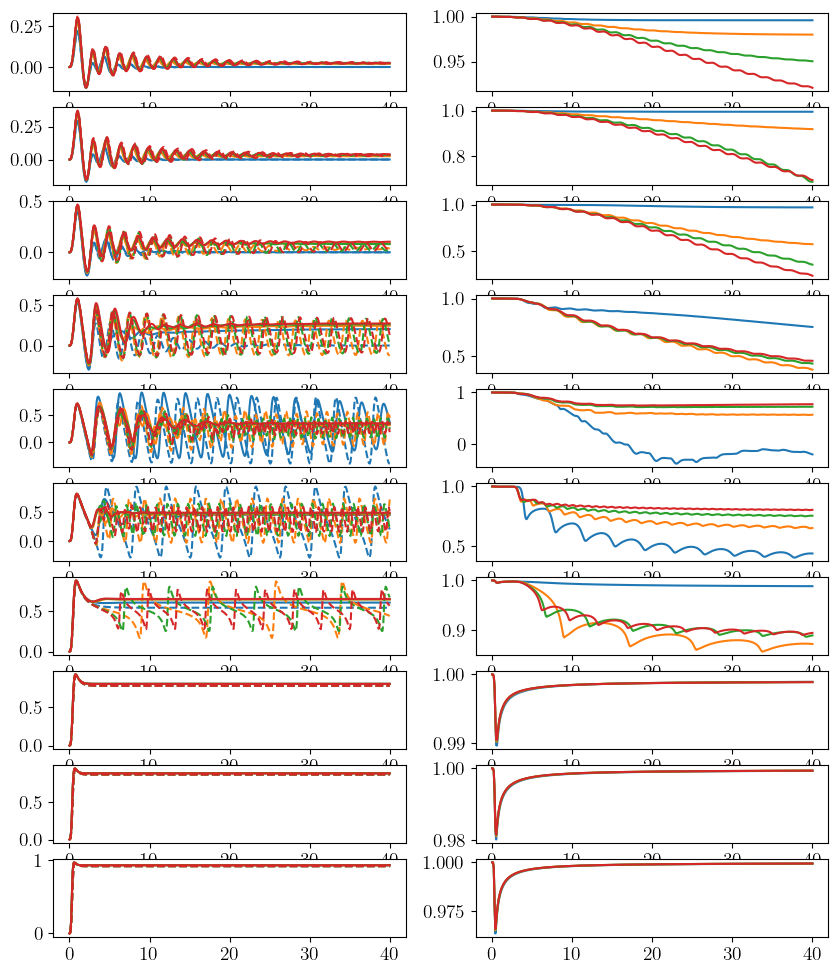

In [182]:

fig, ax = plt.subplots(ncols=2,nrows=len(omega_list),figsize=[10,12])
N_list=[2,4,6,8]
J=4.0
for iw, omega in enumerate(omega_list):
    print(f"$\gamma_1 = {omega**2*0.1/2}, \gamma_2 = {16*0.1/2}$")
    for nn, N in enumerate(N_list):
        ax[iw,0].plot(times, data[N,J,omega,'ps_exp'].mean(axis=0), c=f'C{nn}')        
        ax[iw,0].plot(times, data[N,J,omega,'eff_exp'].mean(axis=0), '--', c=f'C{nn}')
                      
        #ax[iw,1].plot(times, np.cumsum(np.abs(data[N,J,omega,'ps_exp']-data[N,J,omega,'eff_exp']
        #                                     ).mean(axis=0))/np.cumsum(np.arange(1,len(times)+1)))
        err = 1-(np.cumsum((np.abs(data[N,J,omega,'ps_exp']-data[N,J,omega,'eff_exp'])**2).mean(axis=0))/
                                             np.cumsum((data[N,J,omega,'eff_exp']**2).mean(axis=0)))
        
        ax[iw,1].plot(times,err)
         
        #ax[iw,2].plot(times, np.cumsum(np.abs(data[N,J,omega,'ps_ee']-data[N,J,omega,'eff_ee']
        #                                     ))/np.cumsum(np.arange(1,len(times)+1)))
        #ax[iw,2].semilogy(times[1:],np.cumprod(data[N,J,omega,'ps_rdm'][1:]))
        fit_result = fit_success_prob(times[1:],np.cumprod(data[N,J,omega,'ps_rdm'][1:]))
        y_fit  = np.exp(_exp_decay(times, fit_result["A"],
                            fit_result["gamma"]))
        data[N,J,omega,'rate']= fit_result["gamma"]
        #ax[iw,2].semilogy(times,y_fit,'k--')

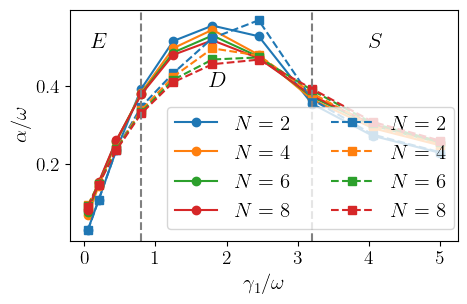

In [143]:
fig, ax = plt.subplots(figsize=[5,3])
J=4.0
for N in N_list:
    ax.plot(omega_list**2*0.1/2,np.array([data[N,J,omega,'rate'] for omega in omega_list])/N,'o-',
             label=rf"$N={N}$")
    
    
J=7.0
for nn, N in enumerate(N_list):
    ax.plot(omega_list**2*0.1/2,np.array([data[N,J,omega,'rate'] for omega in omega_list])/N,'s--',
             color=f'C{nn}',label=rf"$N={N}$")

ax.set_xlabel(r"$\gamma_1/\omega$")
ax.set_ylabel(r"$\alpha/\omega$")
ax.legend(loc=[0.25,0.05],ncols=2,numpoints=1,)
a,b=ax.set_ylim()
ax.axvline(0.8,ls='--',color='gray')
ax.axvline(3.2,ls='--',color='gray')
ax.annotate(r"$E$",xy=(0.1,0.5),fontsize=16)
ax.annotate(r"$S$",xy=(4,0.5),fontsize=16)
ax.annotate(r"$D$",xy=(1.75,0.4),fontsize=16)
fig.savefig('decay_rate.pdf',bbox_inches='tight')

$\gamma_1 = 0.05, \gamma_2 = 0.8$
$\gamma_1 = 0.2, \gamma_2 = 0.8$
$\gamma_1 = 0.45, \gamma_2 = 0.8$
$\gamma_1 = 0.8, \gamma_2 = 0.8$
$\gamma_1 = 1.25, \gamma_2 = 0.8$
$\gamma_1 = 1.8, \gamma_2 = 0.8$
$\gamma_1 = 2.45, \gamma_2 = 0.8$
$\gamma_1 = 3.2, \gamma_2 = 0.8$
$\gamma_1 = 4.05, \gamma_2 = 0.8$
$\gamma_1 = 5.0, \gamma_2 = 0.8$


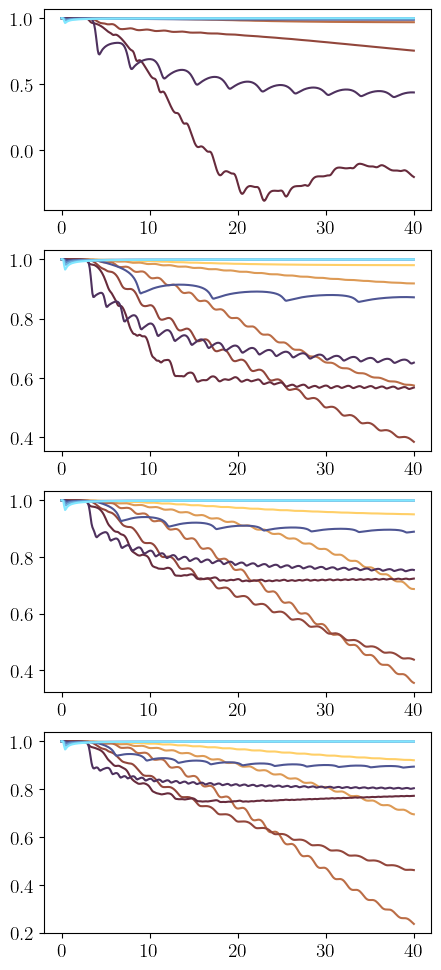

In [41]:

fig, ax = plt.subplots(nrows=len(N_list),figsize=[5,12])
N_list=[2,4,6,8]
J=4.0
colors = plt.cm.managua(np.linspace(0,1,len(omega_list)))
for iw, omega in enumerate(omega_list):
    print(f"$\gamma_1 = {omega**2*0.1/2}, \gamma_2 = {16*0.1/2}$")
    for nn, N in enumerate(N_list):
   
        err = 1-(np.cumsum((np.abs(data[N,J,omega,'ps_exp']-data[N,J,omega,'eff_exp'])**2).mean(axis=0))/
                                             np.cumsum((data[N,J,omega,'eff_exp']**2).mean(axis=0)))
        
        ax[nn].plot(times,err,c=colors[iw])
        data[N,J,omega,'err']=err 
        #ax[iw,2].plot(times, np.cumsum(np.abs(data[N,J,omega,'ps_ee']-data[N,J,omega,'eff_ee']
        #                                     ))/np.cumsum(np.arange(1,len(times)+1)))
        #ax[iw,2].semilogy(times[1:],np.cumprod(data[N,J,omega,'ps_rdm'][1:]))

        #ax[iw,2].semilogy(times,y_fit,'k--')

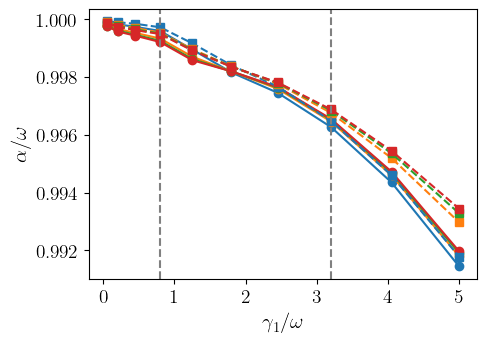

In [224]:
fig, ax = plt.subplots(figsize=[5,3.5])
J=4.0
for N in N_list:
    ax.plot(omega_list**2*0.1/2,np.array([data[N,J,omega,'err'][20] for omega in omega_list]),'o-',
             label=rf"$N={N}$")
    
    
J=7.0
for nn, N in enumerate(N_list):
    ax.plot(omega_list**2*0.1/2,np.array([data[N,J,omega,'err'][20] for omega in omega_list]),'s--',
             color=f'C{nn}',label=rf"$N={N}$")

ax.set_xlabel(r"$\gamma_1/\omega$")
ax.set_ylabel(r"$\alpha/\omega$")
#ax.legend(loc=[1.01,0.05],ncols=2,numpoints=1,)
a,b=ax.set_ylim()
ax.axvline(0.8,ls='--',color='gray')
ax.axvline(3.2,ls='--',color='gray')
ax.annotate(r"$E$",xy=(0.1,0.5),fontsize=16)
ax.annotate(r"$S$",xy=(4,0.5),fontsize=16)
ax.annotate(r"$D$",xy=(1.75,0.4),fontsize=16)
fig.savefig('err_shorttime.pdf',bbox_inches='tight')

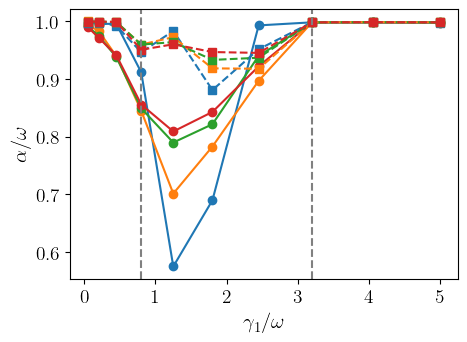

In [225]:
fig, ax = plt.subplots(figsize=[5,3.5])
J=4.0
for N in N_list:
    ax.plot(omega_list**2*0.1/2,np.array([data[N,J,omega,'err'][100] for omega in omega_list]),'o-',
             label=rf"$N={N}$")
    
    
J=7.0
for nn, N in enumerate(N_list):
    ax.plot(omega_list**2*0.1/2,np.array([data[N,J,omega,'err'][100] for omega in omega_list]),'s--',
             color=f'C{nn}',label=rf"$N={N}$")

ax.set_xlabel(r"$\gamma_1/\omega$")
ax.set_ylabel(r"$\alpha/\omega$")
#ax.legend(loc=[1.01,0.05],ncols=2,numpoints=1,)
a,b=ax.set_ylim()
ax.axvline(0.8,ls='--',color='gray')
ax.axvline(3.2,ls='--',color='gray')
ax.annotate(r"$E$",xy=(0.1,0.5),fontsize=16)
ax.annotate(r"$S$",xy=(4,0.5),fontsize=16)
ax.annotate(r"$D$",xy=(1.75,0.4),fontsize=16)
fig.savefig('err_longtime.pdf',bbox_inches='tight')

C:\Users\matte\AppData\Local\Temp\ipykernel_19924\30355984.py:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


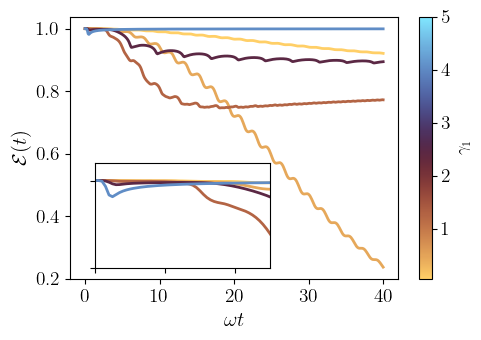

In [48]:

import matplotlib.cm as cm
import matplotlib.colors as mcolors


# --- Parametri ---
param_values = omega_list**2*0.1/2   # valori del parametro
N=8
J=4.0

# --- Colormap e normalizzazione ---
cmap = plt.cm.managua
norm = mcolors.Normalize(vmin=param_values.min(), vmax=param_values.max())

# --- Plot ---
fig, ax = plt.subplots(figsize=(5, 3.5))

for iw, omega in enumerate(omega_list[::2]):
    color = cmap(norm(param_values[2*iw]))        
    ax.plot(times,data[N,J,omega,'err'],c=color,lw=2)

# --- Colorbar ---
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])                        # necessario per ScalarMappable "manuale"
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label(rf"$\gamma_1$", fontsize=12)

ax.set_xlabel(r"$\omega t$")
ax.set_ylabel(r"$\mathcal{E}(t)$")
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

#ax_inset = inset_axes(ax, width="50%", height="40%", loc=[0.2,0.2])
ax_inset = fig.add_axes([0.2, 0.22, 0.35, 0.3])
for iw, omega in enumerate(omega_list[::2]):
    color = cmap(norm(param_values[2*iw]))        
    ax_inset.plot(times,data[N,J,omega,'err'],c=color,lw=2)
ax_inset.set_xticks([0,2,4],["","",""])
ax_inset.set_yticks([0.9,1],["",""])
ax_inset.set_xlim(0, 5)   # zoom su una regione
ax_inset.set_ylim(0.9, 1.02)   # zoom su una regione
plt.tight_layout()
plt.show()
fig.savefig('errvstime_N8.pdf',bbox_inches='tight')

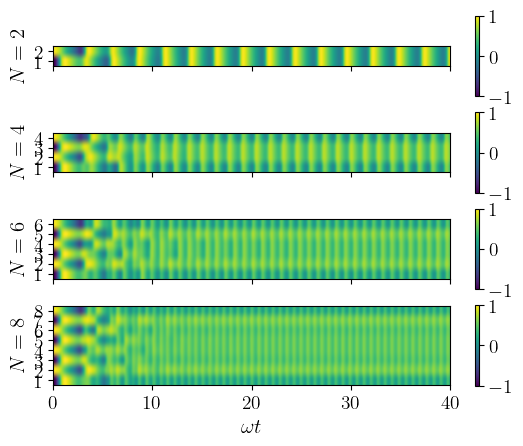

In [38]:
fig, ax = plt.subplots(nrows=len(N_list),sharex=True)
iw, omega = 4,5.0
for nn, N in enumerate(N_list):
    #ax.plot(times, data[N,J,omega,'ps_exp'].mean(axis=0), c=f'C{nn}')        
    #ax[nn].plot(times, data[N,J,omega,'eff_exp'].T, '--', c=f'C{nn}')
    c=ax[nn].imshow(data[N,J,omega,'eff_exp'],extent=[0,times[-1],0.5,N+0.5],aspect='equal')
    fig.colorbar(c)
    ax[nn].set_ylabel(rf'$N={N}$')
    ax[nn].set_yticks(np.arange(1,N+1))
ax[-1].set_xlabel(r'$\omega t$')

fig.savefig('DvsN.pdf',bbox_inches='tight')

In [ ]:
plt.imshow()